Câu 1 (Ý a): Đọc dữ liệu và thêm tiêu đề cho 6 cột

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import numpy as np
import pandas as pd

# Đọc file tb_tracking.xlsx (header=None vì file không có sẵn dòng tiêu đề)
df = pd.read_excel('tb_tracking.xlsx', sheet_name='tb_tracking', header=None)

# Loại bỏ 4 dòng cuối (dòng trống và 3 dòng thống kê Min/Max/Avg của file Excel)
df = df.iloc[:33336].copy()

# Thêm tiêu đề các cột theo đúng thứ tự yêu cầu
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']

display(df.head(10))
df.info()

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039


,id,device_id,co_level,humidity,temperature,time
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01
5,6.0,100.0,2.0,3.0,400.0,2016-12-20 13:02:24
6,7.0,-1.0,0.0,83.0,28.0,2016-12-21 12:03:39
7,8.0,-1.0,0.0,83.0,28.0,2016-12-21 12:05:02
8,9.0,-1.0,0.0,83.0,28.0,2016-12-21 12:05:49
9,10.0,1.0,2.0,3.0,4.0,2016-12-21 12:08:58


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33336 entries, 0 to 33335
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           33336 non-null  float64       
 1   device_id    33336 non-null  float64       
 2   co_level     33336 non-null  float64       
 3   humidity     33336 non-null  float64       
 4   temperature  33336 non-null  float64       
 5   time         33336 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(5)
memory usage: 1.5 MB


Câu 2 (Ý b): Loại bỏ dữ liệu không chính xác trước ngày 03/01/2018

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import pandas as pd

df = pd.read_excel('tb_tracking.xlsx', sheet_name='tb_tracking', header=None)
df = df.iloc[:33336].copy()
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']

# Chuyển cột 'time' về định dạng datetime và lọc dữ liệu từ ngày 03/01/2018 trở đi
df['time'] = pd.to_datetime(df['time'])
df = df[df['time'] >= '2018-01-03'].reset_index(drop=True)

print("Số dòng dữ liệu hợp lệ còn lại:", len(df))
print("Thời gian bắt đầu:", df['time'].min())
print("Thời gian kết thúc:", df['time'].max())
display(df.head(10))

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039
Số dòng dữ liệu hợp lệ còn lại: 1917
Thời gian bắt đầu: 2018-01-03 13:11:07
Thời gian kết thúc: 2018-01-17 15:46:34


,id,device_id,co_level,humidity,temperature,time
0,31420.0,1.0,2.0,3.0,4.0,2018-01-03 13:11:07
1,31421.0,1.0,2.0,3.0,4.0,2018-01-03 13:15:10
2,31422.0,99005.0,58.0,26.0,0.0,2018-01-03 13:17:30
3,31423.0,99005.0,58.0,26.0,0.0,2018-01-03 13:19:21
4,31424.0,99005.0,58.0,26.0,0.0,2018-01-03 13:24:17
5,31425.0,99005.0,60.0,26.0,0.0,2018-01-03 13:29:13
6,31426.0,99005.0,64.0,26.0,0.0,2018-01-03 13:34:10
7,31427.0,99005.0,60.0,27.0,0.0,2018-01-03 14:05:34
8,31428.0,99005.0,60.0,27.0,0.0,2018-01-03 14:10:43
9,31429.0,99005.0,60.0,27.0,0.0,2018-01-03 14:15:39


Câu 3 (Ý c): Bóc tách thời điểm đo đạc trong ngày tính theo phút (minutes)

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import pandas as pd

df = pd.read_excel('tb_tracking.xlsx', sheet_name='tb_tracking', header=None)
df = df.iloc[:33336].copy()
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df['time'] = pd.to_datetime(df['time'])
df = df[df['time'] >= '2018-01-03'].reset_index(drop=True)

# Tạo cột 'minutes' biểu diễn thời điểm đo trong ngày tính theo phút
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute

display(df[['id', 'time', 'minutes', 'co_level', 'humidity', 'temperature']].head(10))
display(df[['minutes', 'co_level', 'humidity', 'temperature']].describe())

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039


,id,time,minutes,co_level,humidity,temperature
0,31420.0,2018-01-03 13:11:07,791,2.0,3.0,4.0
1,31421.0,2018-01-03 13:15:10,795,2.0,3.0,4.0
2,31422.0,2018-01-03 13:17:30,797,58.0,26.0,0.0
3,31423.0,2018-01-03 13:19:21,799,58.0,26.0,0.0
4,31424.0,2018-01-03 13:24:17,804,58.0,26.0,0.0
5,31425.0,2018-01-03 13:29:13,809,60.0,26.0,0.0
6,31426.0,2018-01-03 13:34:10,814,64.0,26.0,0.0
7,31427.0,2018-01-03 14:05:34,845,60.0,27.0,0.0
8,31428.0,2018-01-03 14:10:43,850,60.0,27.0,0.0
9,31429.0,2018-01-03 14:15:39,855,60.0,27.0,0.0


,minutes,co_level,humidity,temperature
count,1917.000000,1917.000000,1917.000000,1.917000e+03
mean,709.297861,28.190662,68.992697,2.358965e+06
std,391.934697,3.997557,12.033094,4.951416e+05
min,1.000000,2.000000,3.000000,0.000000e+00
25%,396.000000,27.000000,61.000000,2.124650e+06
50%,713.000000,28.000000,70.000000,2.331120e+06
75%,993.000000,28.000000,79.000000,2.570550e+06
max,1439.000000,77.000000,86.000000,5.340310e+06


Câu 4 (Ý d): Vẽ đồ thị phân tán (Scatter-plots) cho co_level, humidity, temperature theo minutes

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039


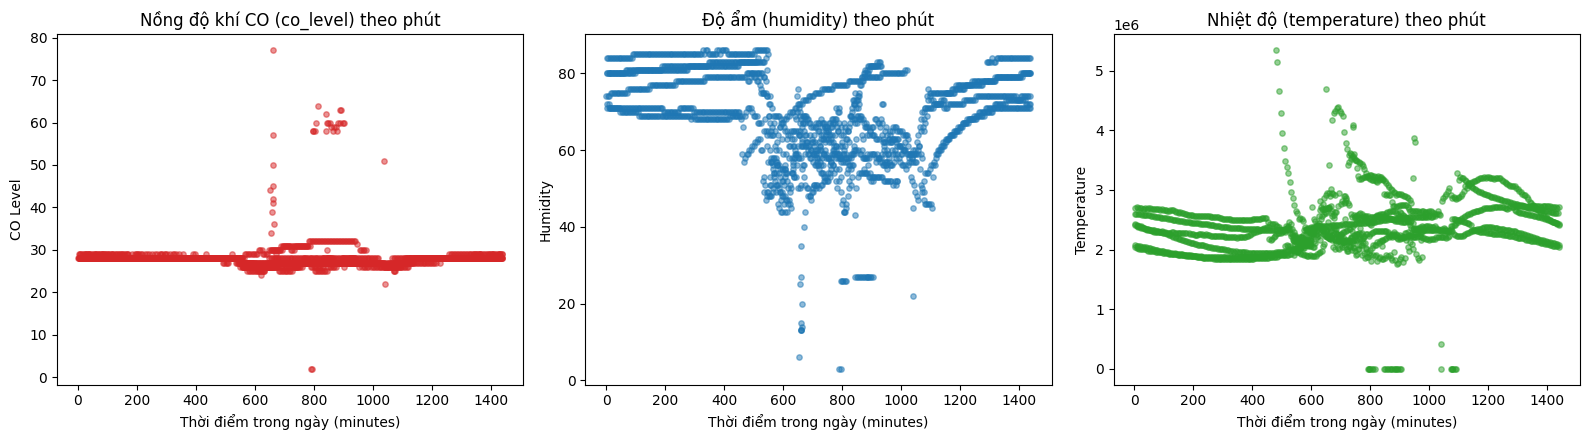

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel('tb_tracking.xlsx', sheet_name='tb_tracking', header=None)
df = df.iloc[:33336].copy()
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df['time'] = pd.to_datetime(df['time'])
df = df[df['time'] >= '2018-01-03'].reset_index(drop=True)
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute

# Vẽ 3 đồ thị phân tán (scatter-plots) lần lượt theo cột minutes
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4.5))

# 1. Nồng độ khí CO theo minutes
axes[0].scatter(df['minutes'], df['co_level'], alpha=0.5, color='tab:red', s=15)
axes[0].set_title('Nồng độ khí CO (co_level) theo phút')
axes[0].set_xlabel('Thời điểm trong ngày (minutes)')
axes[0].set_ylabel('CO Level')

# 2. Độ ẩm theo minutes
axes[1].scatter(df['minutes'], df['humidity'], alpha=0.5, color='tab:blue', s=15)
axes[1].set_title('Độ ẩm (humidity) theo phút')
axes[1].set_xlabel('Thời điểm trong ngày (minutes)')
axes[1].set_ylabel('Humidity')

# 3. Nhiệt độ theo minutes
axes[2].scatter(df['minutes'], df['temperature'], alpha=0.5, color='tab:green', s=15)
axes[2].set_title('Nhiệt độ (temperature) theo phút')
axes[2].set_xlabel('Thời điểm trong ngày (minutes)')
axes[2].set_ylabel('Temperature')

plt.tight_layout()
plt.show()